In [83]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import cv2 as cv

In [84]:
def files(path):
    pasta = Path(path)
    arquivos = [item for item in pasta.iterdir() if not item.is_dir()]
    return arquivos

def dirs(path):
    pasta = Path(path)
    diretorios = [item for item in pasta.iterdir() if item.is_dir()]
    return diretorios

def load_image(path):
    img_bgr = cv.imread(path)
    img_rgb = cv.cvtColor(img_bgr, cv.COLOR_BGR2RGB)
    return img_rgb

def cvt_gray(img_rgb):
    img_gray = cv.cvtColor(img_rgb, cv.COLOR_RGB2GRAY)
    return img_gray


In [85]:
def load_BearingFault_dataset():
    path = "./dataset/bearingfault-dataset/dataset/STFT_spectrograms"

    dados = []

    tamanhos = dirs(path)
    print("Carregando dataset...")

    for tamanho in tamanhos:
        classes = dirs(tamanho)
        for classe in classes:
            rotacoes = dirs(classe)
            for rotacao in rotacoes:
                arquivos = files(rotacao)
                for arquivo in arquivos:
                    dados.append({
                        "Arquivo": str(arquivo),
                        "Tamanho": tamanho.name,
                        "Rotacao": rotacao.name,
                        "Classe": classe.name
                    })

    print("Dados carregados! Criando dataframe...")

    df = pd.DataFrame(dados)

    return df;

df_BearingFault = load_BearingFault_dataset()


Carregando dataset...
Dados carregados! Criando dataframe...


In [86]:
df = df_BearingFault
df.head()

,Arquivo,Tamanho,Rotacao,Classe
0,dataset\bearingfault-dataset\dataset\STFT_spec...,12mm,250,all
1,dataset\bearingfault-dataset\dataset\STFT_spec...,12mm,250,all
2,dataset\bearingfault-dataset\dataset\STFT_spec...,12mm,250,all
3,dataset\bearingfault-dataset\dataset\STFT_spec...,12mm,250,all
4,dataset\bearingfault-dataset\dataset\STFT_spec...,12mm,250,all


Arquivo    dataset\bearingfault-dataset\dataset\STFT_spec...
Tamanho                                                  3mm
Rotacao                                                  350
Classe                                                 outer
Name: 64946, dtype: str


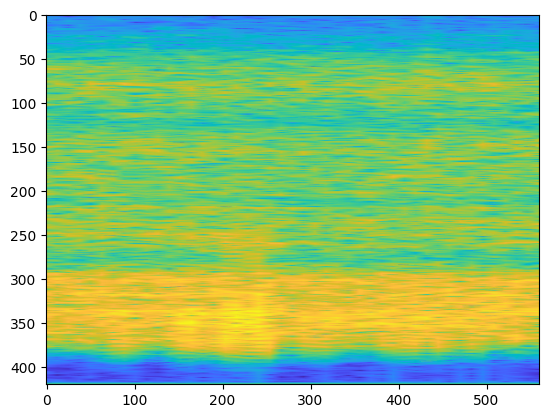

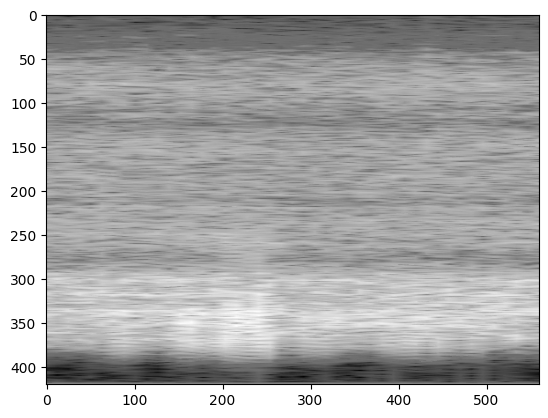

In [87]:
amostra = df.sample().iloc[0]

print(amostra)
amostra_imagem = load_image(amostra["Arquivo"])

plt.imshow(amostra_imagem)
plt.show()

plt.imshow(cvt_gray(amostra_imagem), cmap='gray')
plt.show()
